In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("smartcart_customers.csv")

In [5]:
df.shape

(2240, 22)

In [6]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# Data Preprocessing

# 1 Handle Missing Values

In [7]:
df["Income"]=df["Income"].fillna(df["Income"].median())

In [10]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


# 2 Feature Engineering 

In [14]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response'],
      dtype='object')

As we have the Year_Birth feature but we dont fill as this one is more useful than age 
so we are going to convert the Year_Birth into age 

In [22]:
# Age 
df["Age"]=2026-df["Year_Birth"]

In [23]:
# Customer Joining date
df["Dt_Customer"]=pd.to_datetime(df["Dt_Customer"], dayfirst=True)
ref_date=df["Dt_Customer"].max()
df["Customer_Tenure_days"]=(ref_date-df["Dt_Customer"]).dt.days

In [24]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


In [25]:
# Spending
df["Total_Spending"]=df["MntWines"]+df["MntFruits"]+df["MntMeatProducts"]+df["MntFishProducts"]+df["MntSweetProducts"]+df["MntGoldProds"]

In [26]:
df["Total_Children"]=df["Kidhome"]+df["Teenhome"]

In [34]:
df["Education"].value_counts()

# For Eduction There are three categories like UG, Graduate , PG
df["Education"]=df["Education"].replace({
    "Basic":"Undergraduate",
    "2n Cycle":"Undergraduate",
    "Graduation":"Graduate",
    "Master":"Postgraduate",
    "PhD":"Postgraduate",
})

In [35]:
df["Education"].value_counts()

Education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64

In [38]:
# Martal Status
df["Marital_Status"].value_counts()
df["Living_with"]=df["Marital_Status"].replace({
    "Married":"Partner",
    "Together":"Partner",
    "Single":"Alone",
    "Divorced":"Alone",
    "Widow":"Alone",
    "Alone":"Alone",
    "Absurd":"Alone",
    "YOLO":"Alone",
})

In [41]:
df["Living_with"].value_counts()

Living_with
Partner    1444
Alone       796
Name: count, dtype: int64

In [43]:
col=["ID", "Year_Birth", "Marital_Status","Kidhome", "Teenhome", "Dt_Customer"]
spen=["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
colto_drop=col+spen
df_cleaned=df.drop(columns=colto_drop)

In [47]:
df_cleaned.head()
# df_cleaned.shape

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_days,Total_Spending,Total_Children,Living_with
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


# Outliers

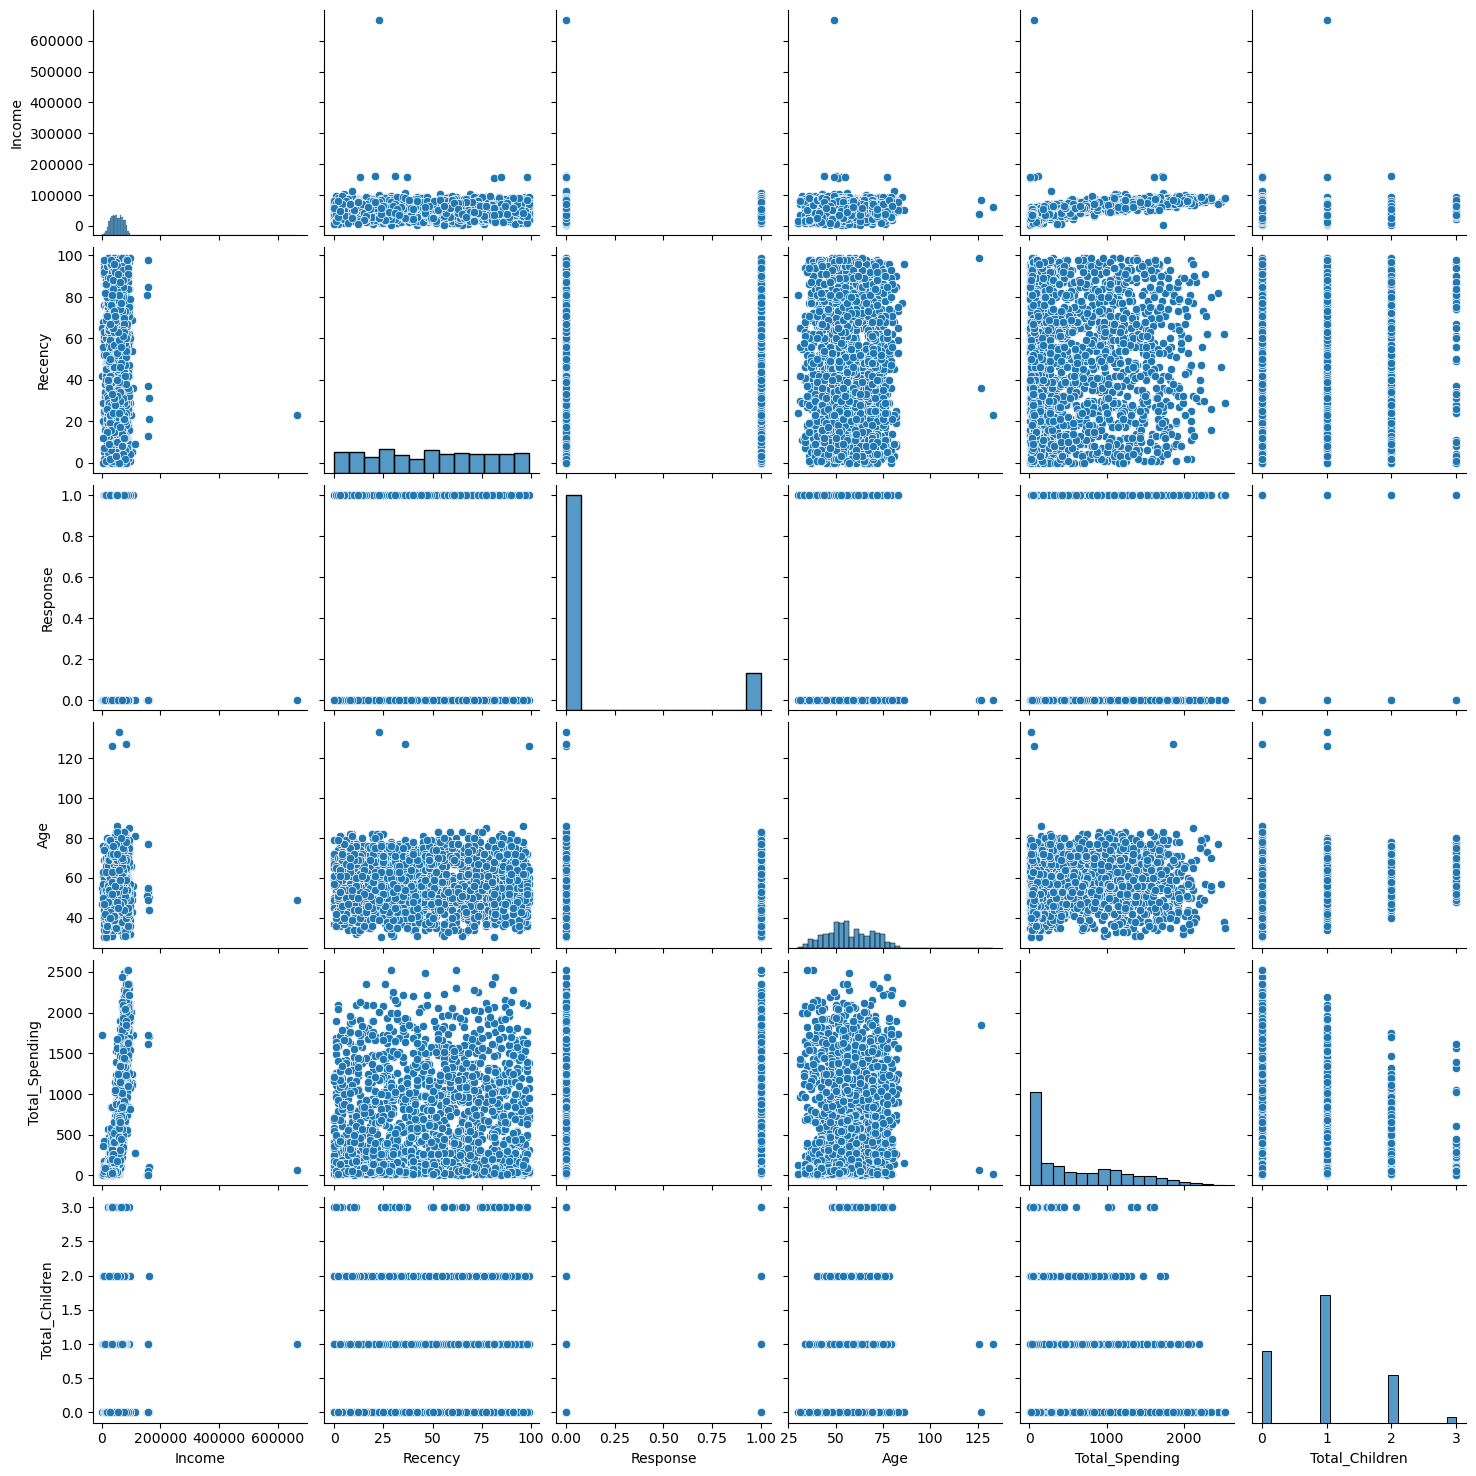

In [50]:
cols=["Income", "Recency", "Response", "Age", "Total_Spending", "Total_Children"]

sns.pairplot(df_cleaned[cols])

In [51]:
# Two outliers are detected 1 income around 600000 2 Age greater then90
print("Data Size with outliers ", len(df_cleaned))

df_cleaned=df_cleaned[(df_cleaned["Age"]<90)] 
df_cleaned=df_cleaned[(df_cleaned["Income"]<600_000)] 

print("Data Size without outliers ", len(df_cleaned))

Data Size with outliers  2240
Data Size without outliers  2236


# Corelation Using Heatmap

In [52]:
corr=df_cleaned.corr(numeric_only=True)

<Axes: >

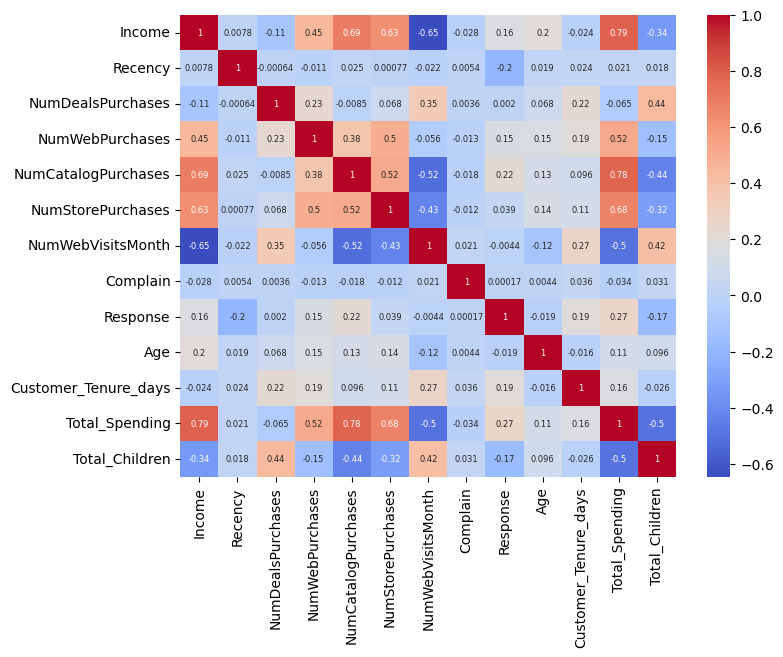

In [62]:
plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size":6},
    cmap="coolwarm"
)

# Encoding

In [64]:
from sklearn.preprocessing import OneHotEncoder

In [66]:
ohe=OneHotEncoder()
cayt_col=["Education","Living_with"]
enc_col=ohe.fit_transform(df_cleaned[cayt_col])

In [72]:
enc_df=pd.DataFrame(enc_col.toarray(), columns=ohe.get_feature_names_out(cayt_col), index=df_cleaned.index)

In [73]:
df_enc=pd.concat([df_cleaned.drop(columns=cayt_col), enc_df], axis=1)

In [74]:
df_enc.shape

(2236, 18)

# Scaling

In [75]:
from sklearn.preprocessing import StandardScaler

In [77]:
X=df_enc

In [79]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

# Visualize

In [81]:
# 2D
from sklearn.decomposition import PCA

In [88]:
pca=PCA(n_components=3)
X_pca=pca.fit_transform(X_scaled)

In [87]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454])

Text(0.5, 0.92, '3D Projection')

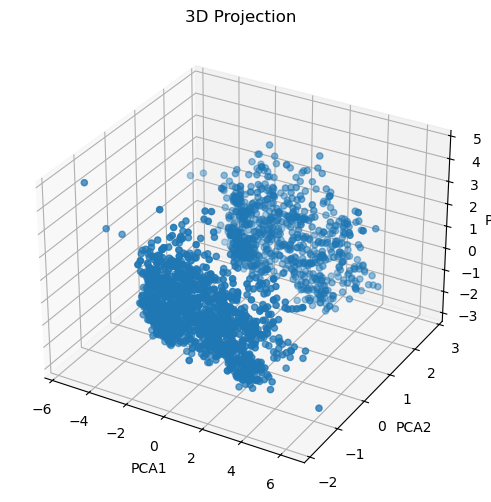

In [92]:
#plot-3D
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111, projection="3d")
ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2])
ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3D Projection")

# Analyze the k value

# 1. Elobow Method

In [96]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss=[]
for k in range(1,11):
    km=KMeans( n_clusters=k, random_state=42)
    km.fit_transform(X_pca)
    wcss.append(km.inertia_)
    

In [100]:
knee=KneeLocator(range(1,11), wcss, curve="convex", direction="decreasing")
optimal_k=knee.elbow

In [102]:
print(optimal_k)

4


# 2.Silhouette Score

In [105]:
from sklearn.metrics import silhouette_score
scores =[]

for k in range(2,11):
    km=KMeans(n_clusters=k, random_state=42)
    lb=km.fit_predict(X_pca)
    score=silhouette_score(X_pca, lb)
    scores.append(score)

Text(0, 0.5, 'Silhouette Score')

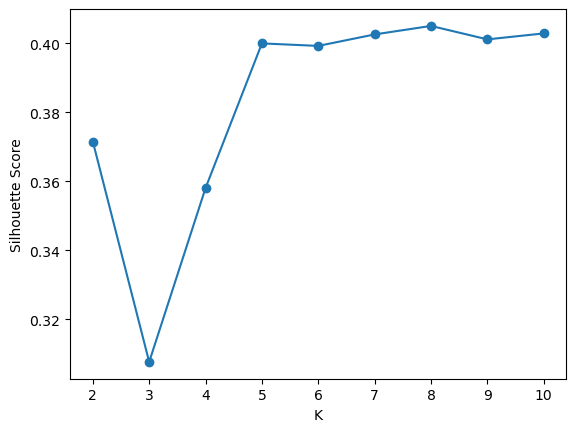

In [106]:
plt.plot(range(2,11), scores, marker="o")
plt.xlabel("K")
plt.ylabel("Silhouette Score")

Text(0, 0.5, 'SS')

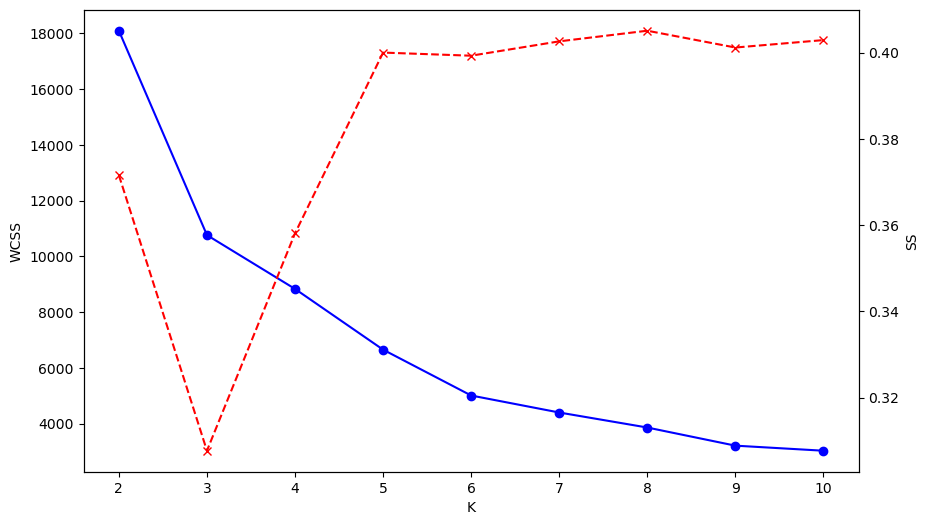

In [112]:
# combined of the both plot
K_range=range(2,11)
fig, ax1=plt.subplots(figsize=(10,6))

ax1.plot(K_range, wcss[:len(K_range)], marker="o", color="blue")
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2=ax1.twinx()
ax2.plot(K_range, scores[:len(K_range)], marker="x", color="red", linestyle="--")
ax2.set_ylabel("SS")

# APPLY CLUSTERING

K means

In [114]:
km=KMeans(n_clusters=4, random_state=42)
lb_km=km.fit_predict(X_pca)

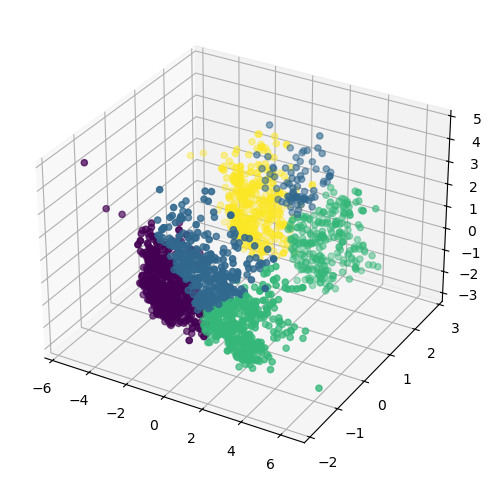

In [115]:
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111, projection="3d")
ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2], c=lb_km)

Aglomerative clustreing

In [117]:
from sklearn.cluster import AgglomerativeClustering

In [118]:
agg=AgglomerativeClustering(n_clusters=4, linkage="ward")
lb_agg=agg.fit_predict(X_pca)

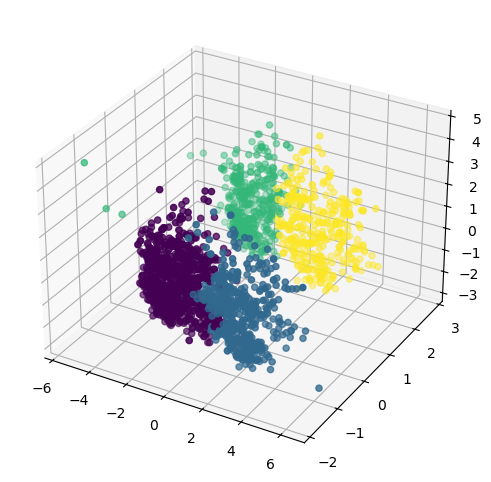

In [119]:
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111, projection="3d")
ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2], c=lb_agg)

# Characterization of The clusters

In [133]:
X["clusters"]=lb_agg

In [134]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_days,Total_Spending,Total_Children,Living_with,labels,clusters
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone,3,3
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone,2,2
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner,1,1
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner,0,0
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner,0,0


<Axes: xlabel='clusters', ylabel='count'>

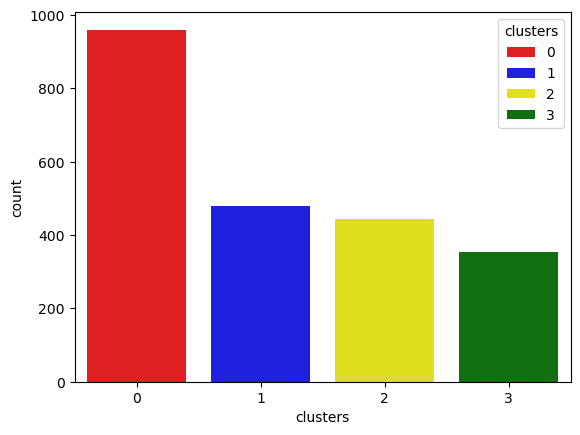

In [135]:
pal=["red", "blue", "yellow", "green"]
sns.countplot(x=X["clusters"], palette=pal, hue=X["clusters"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

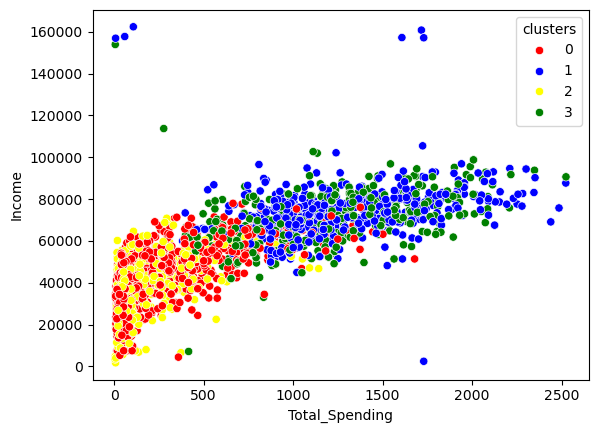

In [136]:
# Income 6 spendinfg patterns 
sns.scatterplot(x=X["Total_Spending"], y=X["Income"], hue=X["clusters"], palette=pal)

In [139]:
# Cluster Summary
cluster_summary = X.groupby("clusters").mean()
print(cluster_summary)

                Income    Recency  NumDealsPurchases  NumWebPurchases  \
clusters                                                                
0         40892.139062  49.251042           2.608333         3.278125   
1         74184.094990  48.561587           1.858038         5.728601   
2         36960.143018  48.319820           2.594595         2.713964   
3         70722.681303  50.504249           1.855524         5.790368   

          NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
clusters                                                                        
0                    1.101042           4.393750           6.244792  0.010417   
1                    5.753653           8.676409           3.392484  0.006263   
2                    0.837838           3.623874           6.659910  0.011261   
3                    5.014164           8.430595           3.728045  0.005666   

          Response        Age  Customer_Tenure_days  Total_Spending  \
clu